In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [131]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [133]:
df[['annual_income','lead_score']] = df[['annual_income','lead_score']].fillna(0)

In [134]:
df[['lead_source','industry','employment_status','location']] = df[['lead_source','industry','employment_status','location']].fillna('NA')

In [135]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   object 
 1   industry                  5000 non-null   object 
 2   employment_status         5000 non-null   object 
 3   location                  5000 non-null   object 
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [136]:
df1 = df.copy()

In [137]:
#del df1['annual_income']

In [138]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [139]:
df_full_train, df_test = train_test_split(df1, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [140]:
df_test = df_test.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
y_test = df_test['converted']
y_train = df_train['converted']
y_val = df_val['converted']
del df_test['converted']
del df_train['converted']
del df_val['converted']

In [145]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
dv.fit(train_dicts)
X_transform = dv.transform(train_dicts)
val_dicts = df_val.to_dict(orient='records')
val_transform = dv.transform(val_dicts)

In [146]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_transform, y_train)

LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

In [149]:
prediction = model.predict_proba(val_transform)[:,1]
y_pred = (prediction >= 0.5).astype(int)

In [150]:
from sklearn.metrics import roc_curve

In [151]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

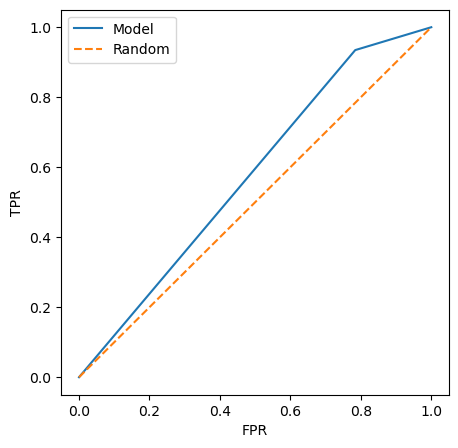

In [152]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [153]:
from sklearn.metrics import auc

In [154]:
auc(fpr, tpr).round(3)

np.float64(0.575)

In [155]:
(y_val == y_pred).mean()

np.float64(0.645)

In [86]:
df1.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [88]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
dv.fit(train_dicts)
X_transform = dv.transform(train_dicts)
val_dicts = df_val.to_dict(orient='records')
val_transform = dv.transform(val_dicts)

In [92]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_transform, y_train)

LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

In [93]:
prediction = model.predict_proba(val_transform)[:,1]
y_pred = (prediction > 0.5).astype(int)

In [94]:
(y_val == y_pred).mean()

np.float64(0.645)

In [95]:
auc(fpr, tpr).round(3)

np.float64(0.575)

In [96]:
from sklearn.metrics import roc_auc_score

In [156]:
roc_auc_score(y_val, y_pred)

np.float64(0.5752771300672095)

In [170]:
def precision_recall(y_val, y_pred):
    scores = []
    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        # Handle division by zero safely
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        if (precision + recall) > 0:
            F1 = 2 * ((precision * recall) / (precision + recall))
        else:
            F1 = 0

        scores.append((t, round(precision, 3), round(recall, 3), round(F1,3)))

    columns = ['t', 'precision', 'recall', 'F1']
    df_scores = pd.DataFrame(scores, columns=columns)
    return df_scores


In [171]:
df_rand = precision_recall(y_val, prediction)

In [172]:
df_rand

,t,precision,recall,F1
0,0.00,0.597,1.0,0.748
1,0.01,0.597,1.0,0.748
2,0.02,0.597,1.0,0.748
3,0.03,0.597,1.0,0.748
4,0.04,0.597,1.0,0.748
...,...,...,...,...
96,0.96,0.000,0.0,0.000
97,0.97,0.000,0.0,0.000
98,0.98,0.000,0.0,0.000
99,0.99,0.000,0.0,0.000


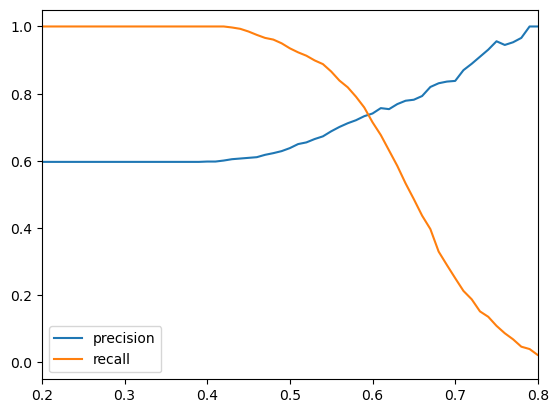

In [173]:

plt.plot(df_rand.t, df_rand['precision'], label='precision')
plt.plot(df_rand.t, df_rand['recall'], label='recall')
plt.legend()
plt.xlim(0.2, 0.8) # Changed from xlims to xlim
plt.show()

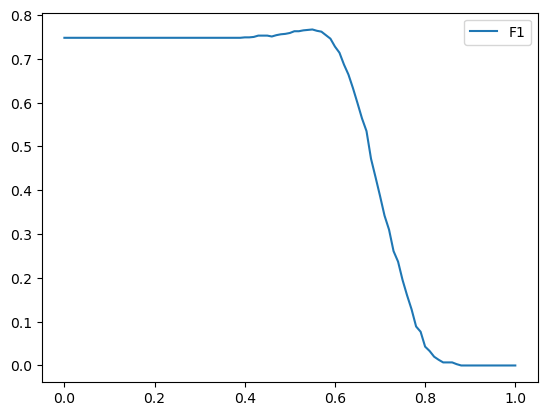

In [174]:
plt.plot(df_rand.t, df_rand['F1'], label='F1')
plt.legend()
plt.show()

In [183]:
df_rand.iloc[21]

t            0.210
precision    0.597
recall       1.000
F1           0.748
Name: 21, dtype: float64

In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   object 
 1   industry                  5000 non-null   object 
 2   employment_status         5000 non-null   object 
 3   location                  5000 non-null   object 
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [185]:
categorical = ['lead_source	industry','employment_status','location']
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

In [199]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [ ]:
df_test = df_test.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
y_test = df_test['converted']
y_train = df_train['converted']
y_val = df_val['converted']
del df_test['converted']
del df_train['converted']
del df_val['converted']

In [200]:
def train(df_train, y_train, C=1.0):
    del df_train['converted']
    dv = DictVectorizer(sparse=False)
    train_dicts = df_train.to_dict(orient='records')
    dv.fit(train_dicts)
    X_transform = dv.transform(train_dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_transform, y_train)
    
    return dv, model

In [201]:
def predict(df, dv, model):
    del df['converted']
    val_dicts = df_val.to_dict(orient='records')
    val_transform = dv.transform(val_dicts)
    y_pred = model.predict_proba(val_transform)[:, 1]

    return y_pred

In [202]:
from tqdm.auto import tqdm
from sklearn.model_selection import KFold

In [205]:
n_splits = 5

for C in [0.000001, 0.001,1]:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.614 +- 0.010
C=0.001 0.783 +- 0.013


C:\Users\omoni\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\omoni\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_

C=1 0.792 +- 0.012


C:\Users\omoni\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
